# Online Retail II — Exploratory Data Analysis

**Objective:** Clean the Online Retail II data and extract actionable insights on revenue, markets, products, and customers.

### Workflow
1. Data loading & inspection
2. Data quality assessment
3. Data cleaning
4. Revenue feature engineering
5. Business analysis
6. Executive dashboard
7. Recommendations

**Cleaning policy:** cancelled invoices, returns, invalid prices, and exact duplicate rows are excluded from the main sales analysis. Missing Customer IDs are retained.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

file_path = Path("../data/raw/online_retail_II.xlsx")
print("Dataset path:", file_path)

Dataset path: ../data/raw/online_retail_II.xlsx


In [4]:
excel_file = pd.ExcelFile(file_path)

df_2009_2010 = pd.read_excel(file_path, sheet_name="Year 2009-2010")
df_2010_2011 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

df = pd.concat([df_2009_2010, df_2010_2011], ignore_index=True)

print("Sheets:", excel_file.sheet_names)
print("2009-2010:", df_2009_2010.shape)
print("2010-2011:", df_2010_2011.shape)
print("Combined:", df.shape)

Sheets: ['Year 2009-2010', 'Year 2010-2011']
2009-2010: (525461, 8)
2010-2011: (541910, 8)
Combined: (1067371, 8)


## 1. Initial Data Exploration

In [5]:
display(df.head())
display(df.tail())

print("\nData types:")
df.info()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France



Data types:
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [6]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2)
}).sort_values("Missing %", ascending=False)

display(missing_summary)

print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Unique countries:", df["Country"].nunique())

,Missing Count,Missing %
Customer ID,243007,22.77
Description,4382,0.41
Invoice,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Unique countries: 43


## 2. Data Quality Assessment

In [7]:
cancelled_mask = df["Invoice"].astype(str).str.startswith("C")
return_mask = df["Quantity"] < 0
zero_price_mask = df["Price"] == 0
negative_price_mask = df["Price"] < 0
duplicate_mask = df.duplicated()

quality_summary = pd.DataFrame({
    "Issue": [
        "Cancelled invoices",
        "Return transactions",
        "Zero-price rows",
        "Negative-price rows",
        "Exact duplicate rows"
    ],
    "Count": [
        cancelled_mask.sum(),
        return_mask.sum(),
        zero_price_mask.sum(),
        negative_price_mask.sum(),
        duplicate_mask.sum()
    ]
})

quality_summary["Percentage"] = (
    quality_summary["Count"] / len(df) * 100
).round(2)

display(quality_summary)

,Issue,Count,Percentage
0,Cancelled invoices,19494,1.83
1,Return transactions,22950,2.15
2,Zero-price rows,6202,0.58
3,Negative-price rows,5,0.00
4,Exact duplicate rows,34335,3.22


### Cleaning decisions

- Cancelled invoices are removed from the main sales analysis.
- Negative quantities are treated as returns; they are stored in `df_returns` and excluded from sales analysis.
- Rows with zero or negative prices are excluded because they cannot contribute valid positive revenue.
- Exact duplicate rows are reduced to one copy.
- Missing Customer IDs are retained as missing values.
- Missing product descriptions are retained because the transaction may still be analytically useful.

In [8]:
df_clean = df.copy()

# Cancelled invoices
cancelled_mask = df_clean["Invoice"].astype(str).str.startswith("C")
cancelled_count = int(cancelled_mask.sum())
df_clean = df_clean.loc[~cancelled_mask].copy()

# Returns
return_mask = df_clean["Quantity"] < 0
df_returns = df_clean.loc[return_mask].copy()
return_count = len(df_returns)
df_clean = df_clean.loc[~return_mask].copy()

# Invalid prices
invalid_price_mask = df_clean["Price"] <= 0
invalid_price_count = int(invalid_price_mask.sum())
df_clean = df_clean.loc[~invalid_price_mask].copy()

# Exact duplicates
duplicate_count = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().copy()

print(f"Cancelled rows removed: {cancelled_count:,}")
print(f"Return rows removed: {return_count:,}")
print(f"Invalid-price rows removed: {invalid_price_count:,}")
print(f"Duplicate rows removed: {duplicate_count:,}")
print(f"Cleaned dataset rows: {len(df_clean):,}")

Cancelled rows removed: 19,494
Return rows removed: 3,457
Invalid-price rows removed: 2,750
Duplicate rows removed: 33,757
Cleaned dataset rows: 1,007,913


In [9]:
validation = pd.Series({
    "Rows": len(df_clean),
    "Columns": len(df_clean.columns),
    "Missing values": int(df_clean.isnull().sum().sum()),
    "Exact duplicates": int(df_clean.duplicated().sum()),
    "Negative quantities": int((df_clean["Quantity"] < 0).sum()),
    "Invalid prices": int((df_clean["Price"] <= 0).sum())
})

display(validation.to_frame("Value"))

,Value
Rows,1007913
Columns,8
Missing values,228488
Exact duplicates,0
Negative quantities,0
Invalid prices,0


## 3. Feature Engineering

In [10]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

print("Revenue created successfully.")
display(df_clean[[
    "Invoice", "StockCode", "Quantity",
    "Price", "Revenue", "Country"
]].head())

print("Negative revenue rows:", int((df_clean["Revenue"] < 0).sum()))
print("Zero revenue rows:", int((df_clean["Revenue"] == 0).sum()))

df_clean.to_csv("cleaned_retail_dataset.csv", index=False)
print("Saved: cleaned_retail_dataset.csv")

Revenue created successfully.


,Invoice,StockCode,Quantity,Price,Revenue,Country
0,489434,85048,12,6.95,83.4,United Kingdom
1,489434,79323P,12,6.75,81.0,United Kingdom
2,489434,79323W,12,6.75,81.0,United Kingdom
3,489434,22041,48,2.10,100.8,United Kingdom
4,489434,21232,24,1.25,30.0,United Kingdom


Negative revenue rows: 0
Zero revenue rows: 0
Saved: cleaned_retail_dataset.csv


## 4. Overall Business Performance

In [11]:
total_revenue = df_clean["Revenue"].sum()
total_quantity = df_clean["Quantity"].sum()

overall_summary = pd.DataFrame({
    "Metric": [
        "Transaction rows", "Total quantity sold", "Total revenue",
        "Average line revenue", "Median line revenue",
        "Unique invoices", "Unique products", "Unique customers", "Countries"
    ],
    "Value": [
        len(df_clean),
        total_quantity,
        round(total_revenue, 2),
        round(df_clean["Revenue"].mean(), 2),
        round(df_clean["Revenue"].median(), 2),
        df_clean["Invoice"].nunique(),
        df_clean["StockCode"].nunique(),
        df_clean["Customer ID"].nunique(),
        df_clean["Country"].nunique()
    ]
})

display(overall_summary)

,Metric,Value
0,Transaction rows,1007913.00
1,Total quantity sold,11205148.00
2,Total revenue,20476260.45
3,Average line revenue,20.32
4,Median line revenue,10.08
5,Unique invoices,40077.00
6,Unique products,4917.00
7,Unique customers,5878.00
8,Countries,43.00


## 5. Revenue & Market Analysis

In [12]:
country_revenue = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

monthly_revenue = (
    df_clean.set_index("InvoiceDate")
    .resample("ME")["Revenue"]
    .sum()
)

print("Top 10 countries by revenue:")
display(country_revenue.head(10).to_frame("Revenue"))

print(
    "Highest revenue month:",
    monthly_revenue.idxmax().strftime("%B %Y"),
    "→",
    f"{monthly_revenue.max():,.2f}"
)

Top 10 countries by revenue:


,Revenue
Country,
United Kingdom,1.741020e+07
EIRE,6.587673e+05
Netherlands,5.540381e+05
Germany,4.250197e+05
France,3.504561e+05
Australia,1.692835e+05
Spain,1.083325e+05
Switzerland,1.006856e+05
Sweden,9.186982e+04


Highest revenue month: November 2011 → 1,503,866.78


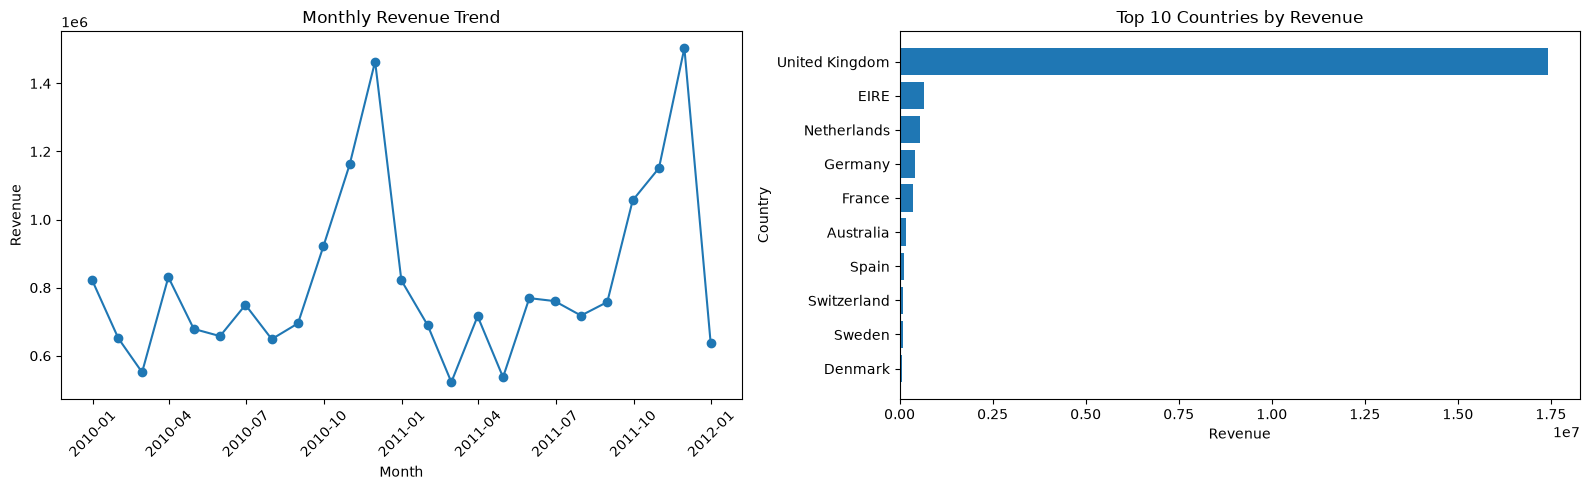

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(monthly_revenue.index, monthly_revenue.values, marker="o")
axes[0].set_title("Monthly Revenue Trend")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue")
axes[0].tick_params(axis="x", rotation=45)

top_countries = country_revenue.head(10).sort_values()
axes[1].barh(top_countries.index, top_countries.values)
axes[1].set_title("Top 10 Countries by Revenue")
axes[1].set_xlabel("Revenue")
axes[1].set_ylabel("Country")

plt.tight_layout()
plt.show()

## 6. Product Analysis

In [14]:
product_revenue = (
    df_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

product_quantity = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

top_products_revenue = product_revenue.head(10)
top_products_quantity = product_quantity.head(10)

print("Top 10 products by revenue:")
display(top_products_revenue.to_frame("Revenue"))

print("Top 10 products by quantity:")
display(top_products_quantity.to_frame("Quantity"))

Top 10 products by revenue:


,Revenue
Description,
Manual,339241.29
REGENCY CAKESTAND 3 TIER,330590.32
DOTCOM POSTAGE,309854.11
WHITE HANGING HEART T-LIGHT HOLDER,260990.22
"PAPER CRAFT , LITTLE BIRDIE",168469.60
PARTY BUNTING,148318.28
JUMBO BAG RED RETROSPOT,148073.47
ASSORTED COLOUR BIRD ORNAMENT,129324.49
POSTAGE,125682.42


Top 10 products by quantity:


,Quantity
Description,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,106139
WHITE HANGING HEART T-LIGHT HOLDER,94658
"PAPER CRAFT , LITTLE BIRDIE",80995
ASSORTED COLOUR BIRD ORNAMENT,80082
MEDIUM CERAMIC TOP STORAGE JAR,78033
JUMBO BAG RED RETROSPOT,77699
BROCADE RING PURSE,70369
PACK OF 60 PINK PAISLEY CAKE CASES,56061
60 TEATIME FAIRY CAKE CASES,54028


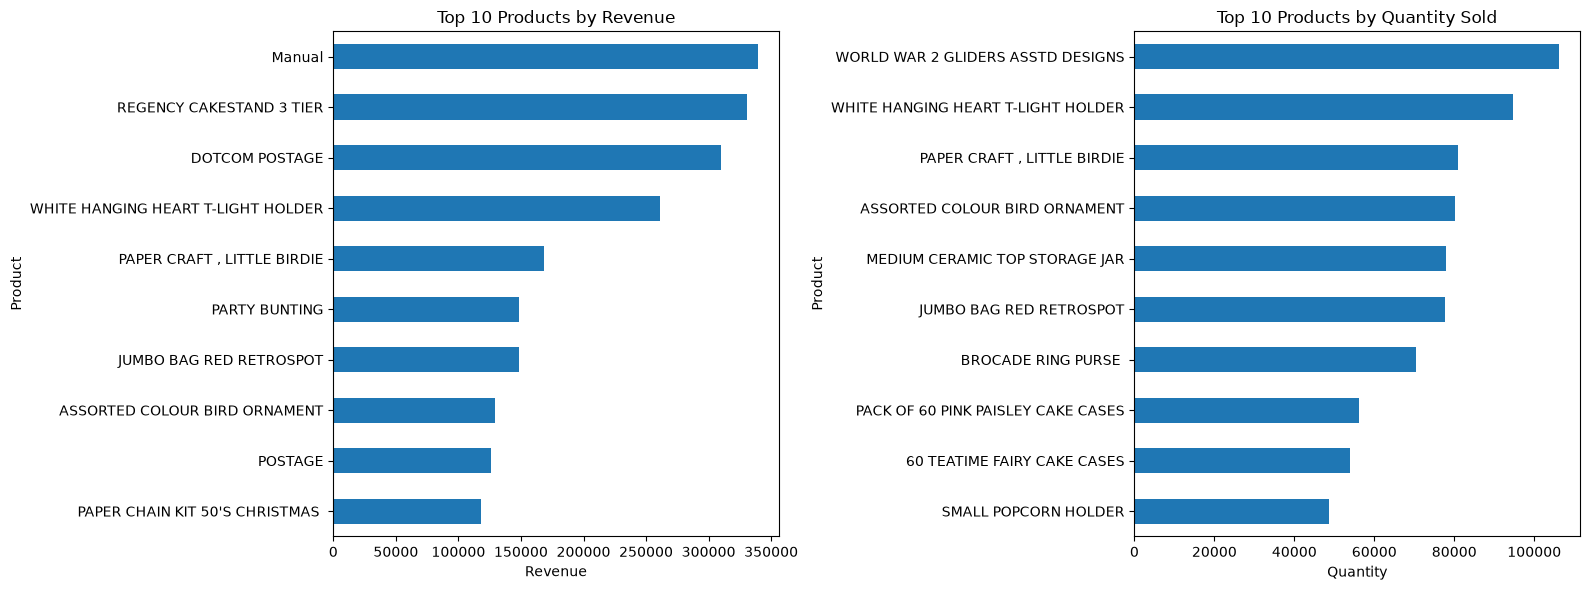

Top revenue product: Manual → 339,241.29
Top volume product: WORLD WAR 2 GLIDERS ASSTD DESIGNS → 106,139 units


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_products_revenue.sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Top 10 Products by Revenue")
axes[0].set_xlabel("Revenue")
axes[0].set_ylabel("Product")

top_products_quantity.sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 10 Products by Quantity Sold")
axes[1].set_xlabel("Quantity")
axes[1].set_ylabel("Product")

plt.tight_layout()
plt.show()

print(
    "Top revenue product:",
    top_products_revenue.index[0],
    "→",
    f"{top_products_revenue.iloc[0]:,.2f}"
)
print(
    "Top volume product:",
    top_products_quantity.index[0],
    "→",
    f"{top_products_quantity.iloc[0]:,} units"
)

## 7. Customer Analysis

In [16]:
customer_df = df_clean.dropna(subset=["Customer ID"])

customer_revenue = (
    customer_df.groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

customer_quantity = (
    customer_df.groupby("Customer ID")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

customer_frequency = (
    customer_df.groupby("Customer ID")["Invoice"]
    .nunique()
    .sort_values(ascending=False)
)

top10_customer_revenue = customer_revenue.head(10)
top10_customer_quantity = customer_quantity.head(10)
top10_customer_frequency = customer_frequency.head(10)

print("Top 10 customers by revenue:")
display(top10_customer_revenue.to_frame("Revenue"))

print("Top 10 customers by quantity:")
display(top10_customer_quantity.to_frame("Quantity"))

print("Top 10 customers by purchase frequency:")
display(top10_customer_frequency.to_frame("Invoices"))

Top 10 customers by revenue:


,Revenue
Customer ID,
18102.0,580987.04
14646.0,528602.52
14156.0,313437.62
14911.0,291420.81
17450.0,244784.25
13694.0,195640.69
17511.0,172132.87
16446.0,168472.50
16684.0,147142.77


Top 10 customers by quantity:


,Quantity
Customer ID,
14646.0,367193
13902.0,220600
13694.0,188201
18102.0,181645
14156.0,164325
14911.0,147972
17511.0,117174
16684.0,104810
14298.0,100272


Top 10 customers by purchase frequency:


,Invoices
Customer ID,
14911.0,398
12748.0,336
17841.0,211
15311.0,208
13089.0,203
14606.0,192
14156.0,156
17850.0,155
14646.0,151


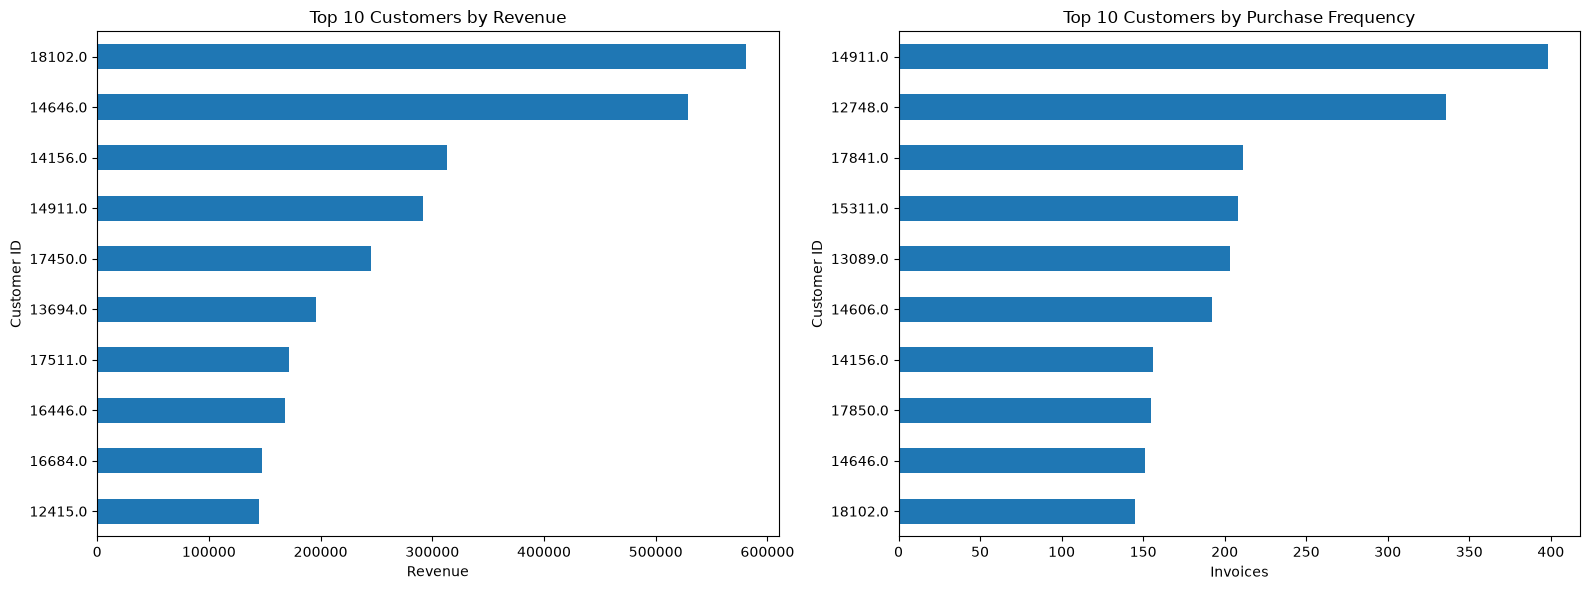

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top10_customer_revenue.sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Top 10 Customers by Revenue")
axes[0].set_xlabel("Revenue")
axes[0].set_ylabel("Customer ID")

top10_customer_frequency.sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 10 Customers by Purchase Frequency")
axes[1].set_xlabel("Invoices")
axes[1].set_ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [18]:
top10_customer_revenue_pct = top10_customer_revenue.sum() / total_revenue * 100
top10_customer_quantity_pct = top10_customer_quantity.sum() / total_quantity * 100

print("Highest-revenue customer:",
      f"{customer_revenue.index[0]:.0f} → {customer_revenue.iloc[0]:,.2f}")

print("Highest-volume customer:",
      f"{customer_quantity.index[0]:.0f} → {customer_quantity.iloc[0]:,} units")

print("Most frequent customer:",
      f"{customer_frequency.index[0]:.0f} → {customer_frequency.iloc[0]:,} invoices")

print(f"Top 10 customer revenue contribution: {top10_customer_revenue_pct:.2f}%")
print(f"Top 10 customer quantity contribution: {top10_customer_quantity_pct:.2f}%")

Highest-revenue customer: 18102 → 580,987.04
Highest-volume customer: 14646 → 367,193 units
Most frequent customer: 14911 → 398 invoices
Top 10 customer revenue contribution: 13.61%
Top 10 customer quantity contribution: 15.03%


## 8. Executive EDA Dashboard

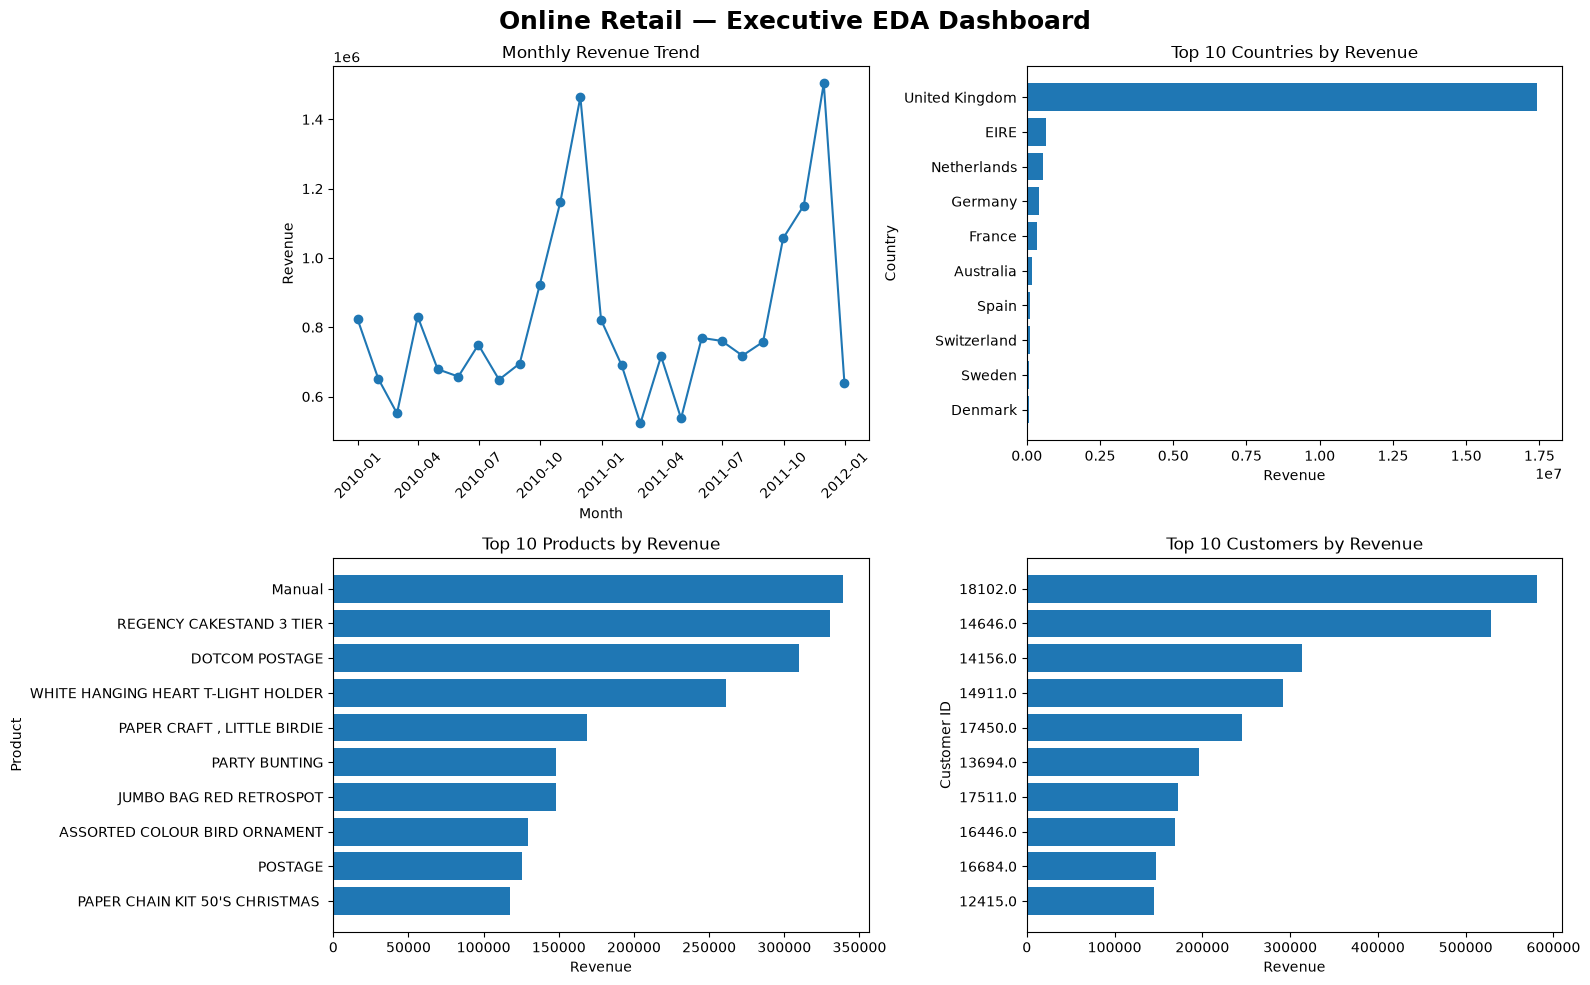

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].plot(monthly_revenue.index, monthly_revenue.values, marker="o")
axes[0, 0].set_title("Monthly Revenue Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Revenue")
axes[0, 0].tick_params(axis="x", rotation=45)

axes[0, 1].barh(
    country_revenue.head(10).index[::-1],
    country_revenue.head(10).values[::-1]
)
axes[0, 1].set_title("Top 10 Countries by Revenue")
axes[0, 1].set_xlabel("Revenue")
axes[0, 1].set_ylabel("Country")

axes[1, 0].barh(
    top_products_revenue.index[::-1],
    top_products_revenue.values[::-1]
)
axes[1, 0].set_title("Top 10 Products by Revenue")
axes[1, 0].set_xlabel("Revenue")
axes[1, 0].set_ylabel("Product")

axes[1, 1].barh(
    top10_customer_revenue.index[::-1].astype(str),
    top10_customer_revenue.values[::-1]
)
axes[1, 1].set_title("Top 10 Customers by Revenue")
axes[1, 1].set_xlabel("Revenue")
axes[1, 1].set_ylabel("Customer ID")

fig.suptitle("Online Retail — Executive EDA Dashboard",
             fontsize=18, fontweight="bold")

plt.tight_layout()
plt.show()

## 9. Final Business Insights & Recommendations

In [20]:
top_country = country_revenue.index[0]
top_product_revenue = product_revenue.index[0]
top_product_quantity = product_quantity.index[0]
top_revenue_customer = int(customer_revenue.index[0])
top_volume_customer = int(customer_quantity.index[0])
top_frequency_customer = int(customer_frequency.index[0])
peak_month = monthly_revenue.idxmax().strftime("%B %Y")

print("=" * 65)
print("BUSINESS INSIGHTS & RECOMMENDATIONS")
print("=" * 65)

print("\n1. MARKET INSIGHT")
print(f"{top_country} is the dominant revenue market.")
print("Recommendation: Maintain strong operations in the core market")
print("while developing other high-performing markets.")

print("\n2. SEASONALITY INSIGHT")
print(f"{peak_month} recorded the highest monthly revenue.")
print("Recommendation: Prepare inventory and marketing before")
print("historically strong demand periods.")

print("\n3. PRODUCT INSIGHT")
print(f"{top_product_revenue} generated the highest revenue.")
print(f"{top_product_quantity} recorded the highest sales volume.")
print("Recommendation: Balance high-revenue products with high-volume")
print("products to improve both margin and sales performance.")

print("\n4. CUSTOMER INSIGHT")
print(f"Customer {top_revenue_customer} generated the highest revenue.")
print(f"Customer {top_frequency_customer} had the highest purchase frequency.")
print(f"Customer {top_volume_customer} purchased the highest quantity.")
print("Recommendation: Use targeted retention and loyalty strategies")
print("for high-value and highly engaged customers.")

print("\n5. CUSTOMER CONCENTRATION")
print(f"Top 10 customers generated {top10_customer_revenue_pct:.2f}% of total revenue.")
print("Recommendation: Retain key customers while expanding the broader")
print("customer base.")

print("\n6. DATA QUALITY")
print("No negative quantities, invalid prices, exact duplicates, or")
print("negative revenue rows remain in the final analysis dataset.")
print("Missing Customer IDs were retained rather than artificially filled.")

print("\n" + "=" * 65)
print("EDA COMPLETED SUCCESSFULLY")
print("=" * 65)

BUSINESS INSIGHTS & RECOMMENDATIONS

1. MARKET INSIGHT
United Kingdom is the dominant revenue market.
Recommendation: Maintain strong operations in the core market
while developing other high-performing markets.

2. SEASONALITY INSIGHT
November 2011 recorded the highest monthly revenue.
Recommendation: Prepare inventory and marketing before
historically strong demand periods.

3. PRODUCT INSIGHT
Manual generated the highest revenue.
WORLD WAR 2 GLIDERS ASSTD DESIGNS recorded the highest sales volume.
Recommendation: Balance high-revenue products with high-volume
products to improve both margin and sales performance.

4. CUSTOMER INSIGHT
Customer 18102 generated the highest revenue.
Customer 14911 had the highest purchase frequency.
Customer 14646 purchased the highest quantity.
Recommendation: Use targeted retention and loyalty strategies
for high-value and highly engaged customers.

5. CUSTOMER CONCENTRATION
Top 10 customers generated 13.61% of total revenue.
Recommendation: Retain ke

In [21]:
# Save final cleaned dataset for the next project phase

import os

output_path = "../data/processed/online_retail_clean.csv"

os.makedirs("../data/processed", exist_ok=True)

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print(f"Location: {output_path}")
print(f"Rows: {len(df_clean):,}")
print(f"Columns: {len(df_clean.columns)}")

Cleaned dataset saved successfully!
Location: ../data/processed/online_retail_clean.csv
Rows: 1,007,913
Columns: 9
